In [ ]:
# Imports
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

In [ ]:
# Use the GPU if available (Runtime -> Change runtime type -> T4 GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [ ]:
# Load CIFAR-10 (50,000 training images and 10,000 test images, 32x32 RGB, 10 classes)
data_path = '/content/data/'
cifar10_train = datasets.CIFAR10(data_path, train=True, download=True, transform=transforms.ToTensor())
cifar10_test = datasets.CIFAR10(data_path, train=False, download=True, transform=transforms.ToTensor())
class_names = cifar10_train.classes
print(class_names)

100%|██████████| 170M/170M [24:11<00:00, 117kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# Stack all images into one tensor (like in the lecture), shape: N x 3 x 32 x 32
train_imgs = torch.stack([img for img, _ in cifar10_train])
test_imgs = torch.stack([img for img, _ in cifar10_test])
train_labels = torch.tensor(cifar10_train.targets)
test_labels = torch.tensor(cifar10_test.targets)

In [ ]:
# Normalization: mean and standard deviation per color channel, computed on the training set only
mean = train_imgs.mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
std = train_imgs.std(dim=(0, 2, 3)).view(1, 3, 1, 1)
print('Mean:', mean.flatten(), '| Std:', std.flatten())
train_imgs = (train_imgs - mean) / std
test_imgs = (test_imgs - mean) / std

Mean: tensor([0.4914, 0.4822, 0.4465]) | Std: tensor([0.2470, 0.2435, 0.2616])


In [ ]:
# Flatten every image into a vector of 3 * 32 * 32 = 3072 values and move everything to the GPU
train_x = train_imgs.view(train_imgs.shape[0], -1).to(device)
test_x = test_imgs.view(test_imgs.shape[0], -1).to(device)
train_y = train_labels.to(device)
test_y = test_labels.to(device)
print('Training set:', train_x.shape, '| Test set:', test_x.shape)

Training set: torch.Size([50000, 3072]) | Test set: torch.Size([10000, 3072])


In [ ]:
# Training configuration (the same for all networks)
batch_size = 64
learning_rate = 1e-3
n_epochs = 50

In [ ]:
# Fully connected network: 3072 inputs -> hidden layers -> 10 outputs (one per class)
def build_mlp(hidden_sizes, activation=nn.ReLU):
    layers = []
    n_in = 3072
    for n_out in hidden_sizes:
        layers.append(nn.Linear(n_in, n_out))
        layers.append(activation())
        n_in = n_out
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
# Loss and accuracy on a whole dataset (in chunks to save GPU memory)
def evaluate(model, x, y, loss_fn):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for i in range(0, len(x), 10000):
            outputs = model(x[i:i + 10000])
            total_loss += loss_fn(outputs, y[i:i + 10000]).item() * len(outputs)
            _, predicted = torch.max(outputs, dim=1)
            correct += (predicted == y[i:i + 10000]).sum().item()
    return total_loss / len(x), correct / len(x)

In [ ]:
# Training loop from the lecture with shuffled minibatches
# After every epoch the loss and accuracy on the training and test set are recorded
# The training time only counts the training steps, not the evaluation
def training_loop(n_epochs, optimizer, model, loss_fn):
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    training_time = 0
    for epoch in range(1, n_epochs + 1):
        model.train()
        start = time.time()
        perm = torch.randperm(len(train_x), device=device)  # shuffle the training data every epoch
        for i in range(0, len(train_x), batch_size):
            idx = perm[i:i + batch_size]
            outputs = model(train_x[idx])
            loss = loss_fn(outputs, train_y[idx])

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        training_time += time.time() - start

        train_loss, train_acc = evaluate(model, train_x, train_y, loss_fn)
        test_loss, test_acc = evaluate(model, test_x, test_y, loss_fn)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        if epoch == 1 or epoch % 10 == 0:
            print(f'Epoch {epoch}, Training loss {train_loss:.4f}, Test loss {test_loss:.4f}, '
                  f'Training accuracy {train_acc:.4f}, Test accuracy {test_acc:.4f}')
    return history, training_time

In [ ]:
# Train one network and collect all results
results = {}

def run_experiment(name, hidden_sizes, activation=nn.ReLU):
    print(f'\n--- {name} ---')
    torch.manual_seed(0)  # same start weights and batch order for every network
    model = build_mlp(hidden_sizes, activation).to(device)
    print(model)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history, training_time = training_loop(n_epochs, optimizer, model, nn.CrossEntropyLoss())

    best_epoch = int(np.argmax(history['test_acc'])) + 1
    results[name] = {'history': history,
                     'Hidden layers': ' - '.join(str(h) for h in hidden_sizes),
                     'Activation': activation.__name__,
                     'Parameters': count_parameters(model),
                     'Training time (s)': training_time,
                     'Training loss': history['train_loss'][-1],
                     'Training accuracy': history['train_acc'][-1],
                     'Test accuracy': history['test_acc'][-1],
                     'Best test accuracy': max(history['test_acc']),
                     'Best epoch': best_epoch}
    r = results[name]
    print(f"Parameters: {r['Parameters']:,} | Training time: {r['Training time (s)']:.1f} s | "
          f"Training loss: {r['Training loss']:.4f} | Training accuracy: {r['Training accuracy']:.4f} | "
          f"Test accuracy: {r['Test accuracy']:.4f} | Best test accuracy: {r['Best test accuracy']:.4f} (epoch {best_epoch})")
    return model

In [ ]:
# Plot loss and accuracy curves (training and test) of one network
def plot_history(name, filename):
    h = results[name]['history']
    epochs = range(1, n_epochs + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs, h['train_loss'], label='Training loss')
    axes[0].plot(epochs, h['test_loss'], label='Test loss')
    axes[0].set_ylabel('Loss (cross entropy)')
    axes[0].set_title('Loss')
    axes[1].plot(epochs, h['train_acc'], label='Training accuracy')
    axes[1].plot(epochs, h['test_acc'], label='Test accuracy')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(True)
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.savefig(filename, dpi=110)
    plt.show()

In [ ]:
# Table with the results of several networks
def results_table(names):
    columns = ['Hidden layers', 'Activation', 'Parameters', 'Training time (s)', 'Training loss',
               'Training accuracy', 'Test accuracy', 'Best test accuracy', 'Best epoch']
    table = pd.DataFrame({n: {c: results[n][c] for c in columns} for n in names}).T
    print(table.to_string(formatters={'Parameters': '{:,}'.format, 'Training time (s)': '{:.1f}'.format,
                                      'Training loss': '{:.4f}'.format, 'Training accuracy': '{:.4f}'.format,
                                      'Test accuracy': '{:.4f}'.format, 'Best test accuracy': '{:.4f}'.format}))

## 1.a) Baseline fully connected network (2 hidden layers)


--- 1.a Baseline (2 hidden layers) ---
Sequential(
  (0): Linear(in_features=3072, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=10, bias=True)
)
Epoch 1, Training loss 1.4821, Test loss 1.5300, Training accuracy 0.4754, Test accuracy 0.4623
Epoch 10, Training loss 0.7922, Test loss 1.4907, Training accuracy 0.7194, Test accuracy 0.5234
Epoch 20, Training loss 0.4914, Test loss 2.1009, Training accuracy 0.8276, Test accuracy 0.5213
Epoch 30, Training loss 0.3344, Test loss 2.8202, Training accuracy 0.8815, Test accuracy 0.5134
Epoch 40, Training loss 0.2642, Test loss 3.2452, Training accuracy 0.9075, Test accuracy 0.5132
Epoch 50, Training loss 0.2191, Test loss 3.8285, Training accuracy 0.9278, Test accuracy 0.5218
Parameters: 1,707,274 | Training time: 60.6 s | Training loss: 0.2191 | Training accuracy: 0.9278 | Test accuracy: 0.5218 | Best test accuracy: 0.5345 (epoch

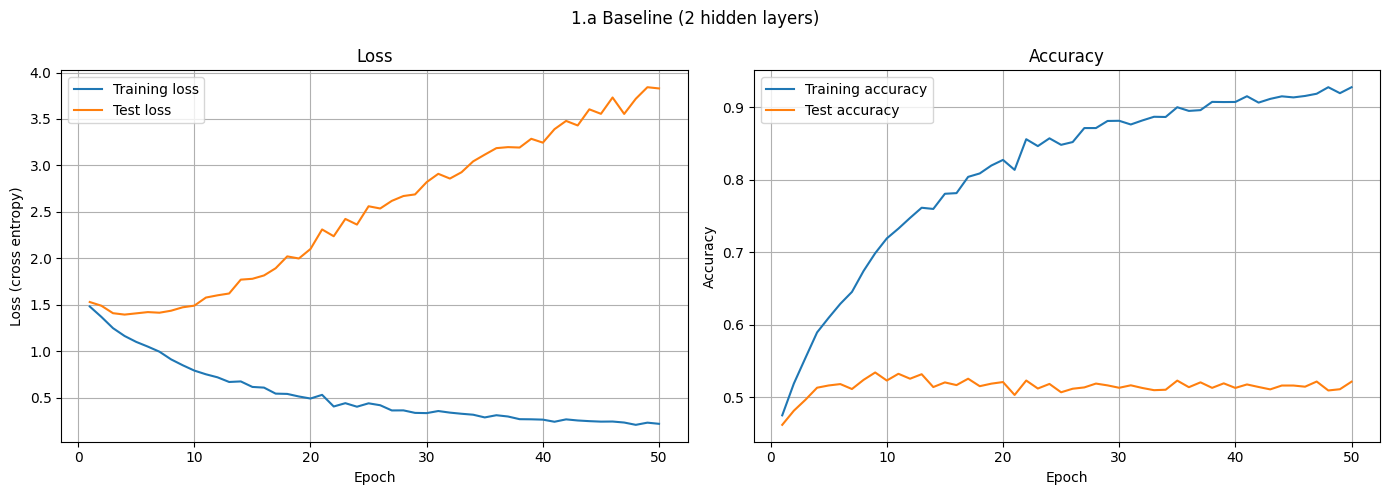

In [ ]:
# Two hidden layers with 512 and 256 neurons and ReLU
run_experiment('1.a Baseline (2 hidden layers)', [512, 256])
plot_history('1.a Baseline (2 hidden layers)', 'problem_1a_curves.png')

## 1.b) Increasing network depth (4 hidden layers)


--- 1.b Deeper (4 hidden layers) ---
Sequential(
  (0): Linear(in_features=3072, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=64, bias=True)
  (7): ReLU()
  (8): Linear(in_features=64, out_features=10, bias=True)
)
Epoch 1, Training loss 1.4697, Test loss 1.5054, Training accuracy 0.4800, Test accuracy 0.4641
Epoch 10, Training loss 0.7683, Test loss 1.4608, Training accuracy 0.7266, Test accuracy 0.5369
Epoch 20, Training loss 0.4059, Test loss 1.9834, Training accuracy 0.8580, Test accuracy 0.5449
Epoch 30, Training loss 0.2625, Test loss 2.4665, Training accuracy 0.9096, Test accuracy 0.5349
Epoch 40, Training loss 0.2021, Test loss 2.8025, Training accuracy 0.9315, Test accuracy 0.5366
Epoch 50, Training loss 0.1846, Test loss 3.1793, Training accuracy 0.9394, Test accuracy 0.5328
Parameters: 1

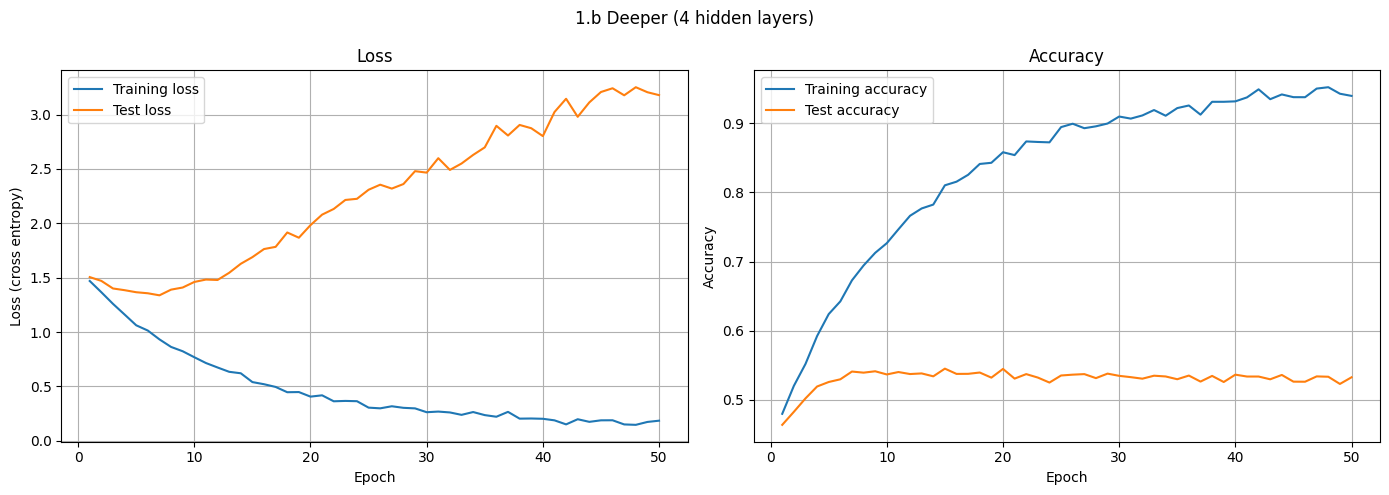

In [19]:
# Two additional hidden layers with 128 and 64 neurons (each followed by ReLU)
run_experiment('1.b Deeper (4 hidden layers)', [512, 256, 128, 64])
plot_history('1.b Deeper (4 hidden layers)', 'problem_1b_curves.png')

In [20]:
# Comparison of 1.a and 1.b
results_table(['1.a Baseline (2 hidden layers)', '1.b Deeper (4 hidden layers)'])

                                       Hidden layers Activation Parameters Training time (s) Training loss Training accuracy Test accuracy Best test accuracy Best epoch
1.a Baseline (2 hidden layers)             512 - 256       ReLU  1,707,274              60.6        0.2191            0.9278        0.5218             0.5345          9
1.b Deeper (4 hidden layers)    512 - 256 - 128 - 64       ReLU  1,746,506              80.8        0.1846            0.9394        0.5328             0.5453         15


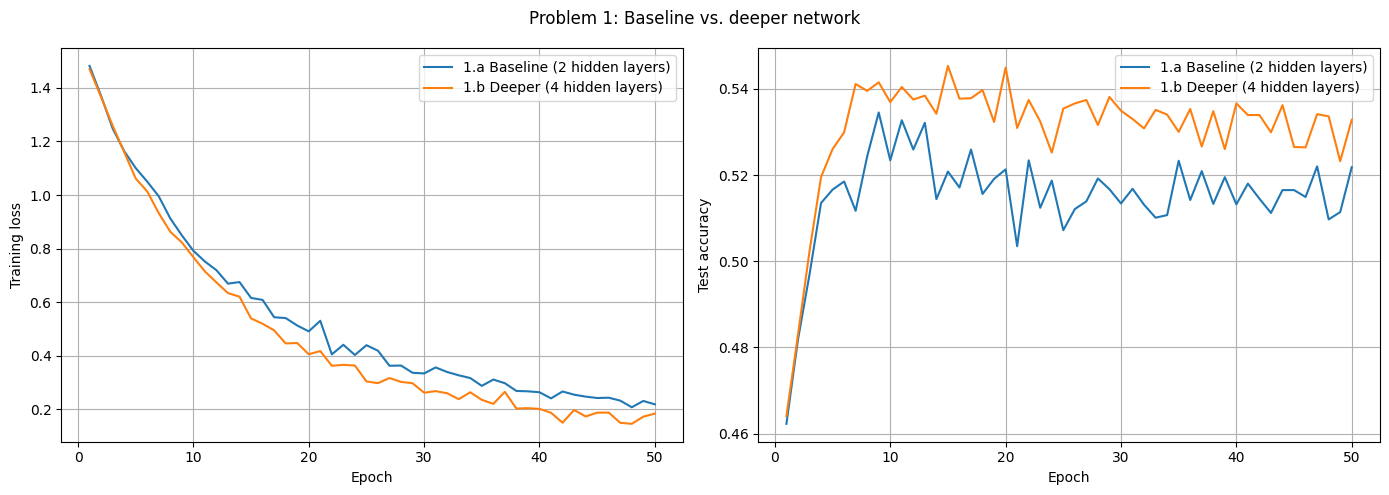

In [21]:
# Test accuracy and training loss of both networks in one plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ['1.a Baseline (2 hidden layers)', '1.b Deeper (4 hidden layers)']:
    axes[0].plot(range(1, n_epochs + 1), results[name]['history']['train_loss'], label=name)
    axes[1].plot(range(1, n_epochs + 1), results[name]['history']['test_acc'], label=name)
axes[0].set_ylabel('Training loss')
axes[1].set_ylabel('Test accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()
fig.suptitle('Problem 1: Baseline vs. deeper network')
plt.tight_layout()
plt.savefig('problem_1_comparison.png', dpi=110)
plt.show()